# 01 — Explorar a contagem de palavras

Lê a tabela gerada pelo `contar_palavras.py` e responde:

1. Quantas palavras de cada lista passam do **mínimo de ocorrências** em cada período?
2. **2008, 2009 e 2010** sozinhos têm texto suficiente, ou é melhor agrupá-los?
3. Quais palavras das listas pequenas (gênero, ocupações, inteligência, aparência) ficam de fora em cada período?
4. Quantos **trechos** a extração vai processar de verdade em cada opção da PP3, e quanto tempo de GPU isso custa?

Rode a partir da pasta `TCC` (onde está este notebook). Todos os parâmetros estão na próxima célula.

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
from palavras_alvo import carregar_listas

# ---------------- PARÂMETROS (mude aqui e rode tudo de novo) ----------------
MINIMO = 50                 # ocorrências mínimas por palavra e período (Garg: word1lims = [50, ...])
TETO = 500                  # trechos sorteados por palavra e período (Lucy et al. 2022)
SEGUNDOS_POR_TRECHO = 0.078 # medido no teste_tempo.py (BERT, MX330, 50 palavras de cada lado)
N_MODELOS = 3

contagem = pd.read_csv("data/contagem/contagem_palavras.csv")
totais = pd.read_csv("data/contagem/totais.csv")
listas = carregar_listas()
{nome: len(p) for nome, p in listas.items()}

{'masculino': 20,
 'feminino': 20,
 'ocupacoes': 76,
 'ocupacoes_profissionais': 34,
 'ocupacoes_mturk': 47,
 'inteligencia': 28,
 'aparencia': 25,
 'tracos_personalidade': 423,
 'williams_best': 230}

## Tamanho de cada ano (posts e palavras)

In [15]:
totais.groupby("ano")[["posts", "palavras"]].sum().style.format("{:,}")

,posts,palavras
ano,,
2008,"9,960","446,300"
2009,"42,733","2,274,720"
2010,"185,101","11,300,927"
2011,"547,390","33,405,629"
2012,"1,007,944","59,750,702"
2013,"1,280,098","78,151,888"
2014,"1,694,448","107,935,107"
2015,"1,841,087","119,968,083"
2016,"2,182,060","127,789,195"


## Duas formas de dividir o tempo

- **anual**: cada ano é um período (11 períodos).
- **agrupado**: 2008, 2009 e 2010 viram um período só, `2008-10` (9 períodos).

In [16]:
def periodo_anual(ano):
    return str(ano)

def periodo_agrupado(ano):
    return "2008-10" if ano <= 2010 else str(ano)

DIVISOES = {"anual": periodo_anual, "agrupado": periodo_agrupado}

def por_periodo(divisao, por_comunidade=False):
    """Soma as contagens dentro de cada período (e comunidade, se pedido)."""
    c = contagem.assign(periodo=contagem["ano"].map(DIVISOES[divisao]))
    chaves = ["periodo", "palavra"] + (["categoria"] if por_comunidade else [])
    return c.groupby(chaves, as_index=False)[["ocorrencias", "posts"]].sum()

## 1 e 2. Quantas palavras de cada lista passam do mínimo, por período

In [17]:
def cobertura(divisao):
    c = por_periodo(divisao)
    periodos = sorted(c["periodo"].unique())
    tabela = {}
    for nome, palavras in listas.items():
        ok = c[c["palavra"].isin(palavras) & (c["ocorrencias"] >= MINIMO)]
        n_por_periodo = ok.groupby("periodo")["palavra"].nunique().reindex(periodos, fill_value=0)
        tabela[f"{nome} ({len(palavras)})"] = n_por_periodo
    return pd.DataFrame(tabela).T

for divisao in DIVISOES:
    print(f"\n=== {divisao}: nº de palavras com pelo menos {MINIMO} ocorrências ===")
    display(cobertura(divisao))


=== anual: nº de palavras com pelo menos 50 ocorrências ===


periodo,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018
masculino (20),13,15,18,19,20,20,20,20,20,20,20
feminino (20),11,16,17,19,20,20,20,20,20,20,20
ocupacoes (76),6,12,26,38,52,58,63,66,66,66,70
ocupacoes_profissionais (34),5,8,15,20,26,29,31,31,31,30,31
ocupacoes_mturk (47),5,8,16,23,34,39,43,45,44,44,45
inteligencia (28),0,5,11,12,16,19,21,23,22,24,24
aparencia (25),2,8,15,18,21,22,23,23,23,24,25
tracos_personalidade (423),20,112,238,317,347,369,384,391,389,397,396
williams_best (230),11,62,136,179,193,203,212,218,218,222,224



=== agrupado: nº de palavras com pelo menos 50 ocorrências ===


periodo,2008-10,2011,2012,2013,2014,2015,2016,2017,2018
masculino (20),19,19,20,20,20,20,20,20,20
feminino (20),18,19,20,20,20,20,20,20,20
ocupacoes (76),32,38,52,58,63,66,66,66,70
ocupacoes_profissionais (34),17,20,26,29,31,31,31,30,31
ocupacoes_mturk (47),19,23,34,39,43,45,44,44,45
inteligencia (28),11,12,16,19,21,23,22,24,24
aparencia (25),15,18,21,22,23,23,23,24,25
tracos_personalidade (423),264,317,347,369,384,391,389,397,396
williams_best (230),149,179,193,203,212,218,218,222,224


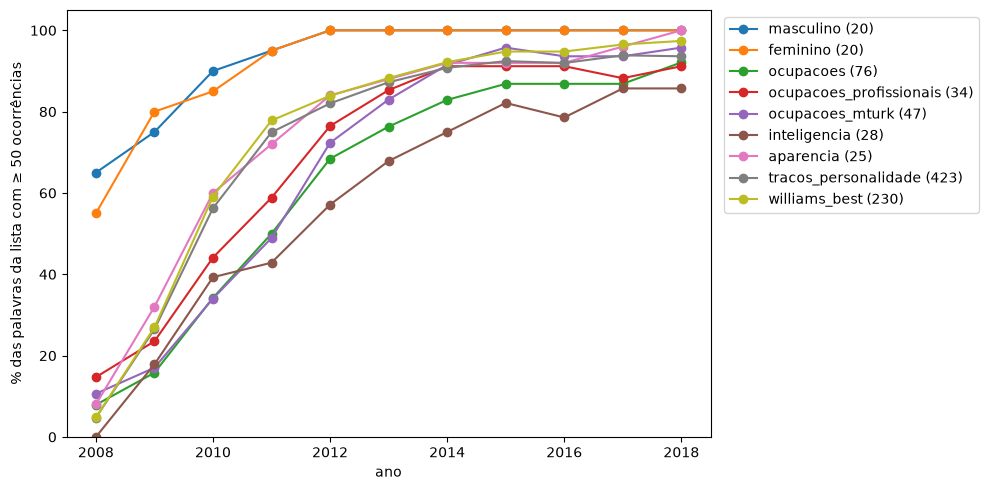

In [18]:
# O mesmo em %, num gráfico, para a divisão anual
tab = cobertura("anual")
tamanhos = {f"{n} ({len(p)})": len(p) for n, p in listas.items()}
pct = tab.div(pd.Series(tamanhos), axis=0) * 100
ax = pct.T.plot(figsize=(10, 5), marker="o")
ax.set_ylabel(f"% das palavras da lista com ≥ {MINIMO} ocorrências")
ax.set_xlabel("ano")
ax.set_ylim(0, 105)
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()

## 3. Quais palavras das listas pequenas ficam de fora

Células em vermelho = abaixo do mínimo naquele período (a palavra sai daquele período, como no Garg).

In [19]:
def faltantes(nome_lista, divisao="agrupado"):
    c = por_periodo(divisao)
    tab = (c[c["palavra"].isin(listas[nome_lista])]
           .pivot(index="palavra", columns="periodo", values="ocorrencias")
           .reindex(listas[nome_lista]).fillna(0).astype(int))
    tab = tab.loc[tab.min(axis=1).sort_values().index]   # as mais raras primeiro
    return tab.style.map(lambda v: "background-color: #fbebeb" if v < MINIMO else "")

for nome in ["masculino", "feminino", "inteligencia", "aparencia"]:
    print(f"\n=== {nome} ===")
    display(faltantes(nome))


=== masculino ===


periodo,2008-10,2011,2012,2013,2014,2015,2016,2017,2018
palavra,,,,,,,,,
nephews,28,40,64,88,129,183,168,277,362
uncles,57,79,121,178,229,303,351,500,628
nephew,87,74,166,201,357,380,384,530,779
uncle,190,360,663,963,1221,1619,1990,2843,3517
brothers,263,602,1158,1469,2542,3141,3557,5945,8883
sons,603,713,1363,1909,2284,2477,2807,3750,5197
brother,890,2195,4322,5220,8647,10014,12244,19751,27982
himself,1590,3295,6130,8299,14607,16291,17266,21507,27885
son,1819,2708,5181,7734,8835,10476,10588,13836,19682



=== feminino ===


periodo,2008-10,2011,2012,2013,2014,2015,2016,2017,2018
palavra,,,,,,,,,
nieces,25,40,66,67,122,143,157,227,324
niece,40,89,151,245,277,331,361,490,589
aunts,54,52,85,144,248,258,335,383,528
aunt,87,189,344,554,739,859,905,1370,1718
sisters,316,475,926,1281,1850,2062,2238,3211,3764
daughters,423,498,1124,1545,2088,2192,2354,3198,4477
hers,597,1343,2165,2763,3828,4848,4442,5051,5750
sister,1078,1938,3915,4441,7290,8320,8487,11464,14482
mothers,1327,2432,4015,5177,5655,6375,6864,9284,12744



=== inteligencia ===


periodo,2008-10,2011,2012,2013,2014,2015,2016,2017,2018
palavra,,,,,,,,,
luminous,0,1,5,6,5,6,6,19,12
venerable,0,2,9,9,31,29,20,24,27
sagacious,1,2,3,2,2,3,6,2,8
judicious,2,10,9,17,42,33,28,40,32
shrewd,3,6,19,23,71,67,75,77,97
precocious,6,15,14,9,18,23,41,56,56
resourceful,9,15,18,60,91,133,134,163,207
imaginative,9,20,41,46,62,63,71,108,93
inventive,12,11,11,27,40,52,48,70,95



=== aparencia ===


periodo,2008-10,2011,2012,2013,2014,2015,2016,2017,2018
palavra,,,,,,,,,
voluptuous,2,6,19,20,32,32,27,71,82
plump,3,11,21,37,60,92,84,128,197
stout,4,11,19,23,27,28,32,39,81
alluring,6,28,44,78,151,134,157,156,210
blushing,14,90,178,159,171,203,180,178,225
slender,16,31,83,126,193,214,194,303,455
feeble,18,38,96,112,181,196,210,295,422
homely,25,39,62,79,224,200,191,258,321
sensual,41,93,151,201,213,262,275,379,426


In [20]:
faltantes("ocupacoes")

periodo,2008-10,2011,2012,2013,2014,2015,2016,2017,2018
palavra,,,,,,,,,
bailiff,0,5,11,13,7,7,17,13,21
auctioneer,0,0,0,0,3,10,4,7,6
shoemaker,0,0,0,3,4,2,6,12,16
surveyor,0,7,11,12,6,14,5,8,14
postmaster,0,1,0,3,6,0,3,1,3
blacksmith,2,5,14,34,28,39,54,60,88
weaver,3,6,5,12,14,27,43,33,65
geologist,3,5,10,17,14,13,13,25,16
conductor,4,13,28,17,49,54,42,47,114


## 4. Quantos trechos a extração vai processar, e quanto tempo

Para cada palavra e período com pelo menos `MINIMO` ocorrências: `min(ocorrências, TETO)` trechos.
Palavras repetidas entre listas são contadas uma vez só.

- **base** = gênero + ocupações + inteligência + aparência (PP1 e PP2)
- **(a)** base + traços de personalidade (PP3 como no Garg)
- **(b)** base + Williams & Best
- **(c)** só a base (PP3 só com inteligência + aparência)

A última coluna simula o sorteio **estratificado por comunidade** (até `TETO` por palavra × período × comunidade, como em Lucy et al. 2022).

In [21]:
base = set(listas["masculino"] + listas["feminino"] + listas["ocupacoes"]
           + listas["inteligencia"] + listas["aparencia"])
OPCOES = {
    "(a) base + traços": base | set(listas["tracos_personalidade"]),
    "(b) base + Williams & Best": base | set(listas["williams_best"]),
    "(c) só base": base,
}

def trechos(palavras, divisao, por_comunidade=False):
    c = por_periodo(divisao, por_comunidade)
    if por_comunidade:   # o mínimo vale para o período inteiro; o teto, para cada comunidade
        validas = por_periodo(divisao)
        validas = validas[validas["ocorrencias"] >= MINIMO][["periodo", "palavra"]]
        c = c.merge(validas, on=["periodo", "palavra"])
    else:
        c = c[c["ocorrencias"] >= MINIMO]
    c = c[c["palavra"].isin(palavras)]
    return int(c["ocorrencias"].clip(upper=TETO).sum())

linhas = []
for divisao in DIVISOES:
    for nome, palavras in OPCOES.items():
        n = trechos(palavras, divisao)
        n_estrat = trechos(palavras, divisao, por_comunidade=True)
        linhas.append({
            "divisão": divisao, "opção": nome, "palavras": len(palavras),
            "trechos (1 modelo)": n,
            f"horas na MX330 ({N_MODELOS} modelos)": round(n * N_MODELOS * SEGUNDOS_POR_TRECHO / 3600, 1),
            "trechos estratificado": n_estrat,
            f"horas estratificado ({N_MODELOS} modelos)": round(n_estrat * N_MODELOS * SEGUNDOS_POR_TRECHO / 3600, 1),
        })
projecao = pd.DataFrame(linhas)
projecao

,divisão,opção,palavras,trechos (1 modelo),horas na MX330 (3 modelos),trechos estratificado,horas estratificado (3 modelos)
0,anual,(a) base + traços,574,1673098,108.8,4095769,266.2
1,anual,(b) base + Williams & Best,382,1129670,73.4,2798023,181.9
2,anual,(c) só base,169,486276,31.6,1284024,83.5
3,agrupado,(a) base + traços,574,1639986,106.6,4063263,264.1
4,agrupado,(b) base + Williams & Best,382,1101401,71.6,2769393,180.0
5,agrupado,(c) só base,169,462169,30.0,1257884,81.8


As horas acima são **na sua MX330**. No Kaggle a GPU é mais rápida: quando medirmos lá o tempo por trecho,
basta trocar `SEGUNDOS_POR_TRECHO` na primeira célula e rodar de novo.

In [22]:
# Quanto cada lista pesa no total de trechos (divisão agrupada, opção (a))
c = por_periodo("agrupado")
c = c[c["ocorrencias"] >= MINIMO].assign(trechos=lambda d: d["ocorrencias"].clip(upper=TETO))
peso = {nome: int(c[c["palavra"].isin(p)]["trechos"].sum()) for nome, p in listas.items()}
pd.Series(peso, name="trechos").sort_values(ascending=False).to_frame()

,trechos
tracos_personalidade,1233152
williams_best,687916
ocupacoes,168231
ocupacoes_mturk,109311
ocupacoes_profissionais,88676
masculino,82051
feminino,80941
aparencia,76018
inteligencia,54928
